# Manuscript figures

Builds every manuscript figure and saves it to `figures/` as PDF and PNG.

1. **Setup**: load the model, simulation and plotting functions.
2. **Plotting parameters**: type sizes and the colour palette shared by every figure.
3. **Simulations**: load the cached runs from `sim_output/`, or rerun them.
4. **Figures 1–4**: one section per figure. Each figure's layout code is here, so edit it here;
   the panel functions it calls live in `paper_figures.py` and `stylised_mechanisms.py`.

`figure_style.save` checks every figure before saving it (standard font sizes, page width, no
text off the page or overlapping), so a layout change that breaks those rules fails loudly.

## 1. Setup

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import figure_style as style
import paper_figures as pf
import stylised_mechanisms as sm
from metrics import (plot_max_error, plot_normalised_pull, plot_steady_state_error,
                     plot_time_outside_band)

## 2. Plotting parameters

Type sizes and line widths come from `figure_style.apply()`. Figures are drawn at their printed
width (`style.PAGE_WIDTH` or `style.COLUMN_WIDTH` inches), so text prints at the same size in
every figure.

**Colours.** `style.PALETTE` maps colour names to hex values. Each module's `COLORS` maps a role
(e.g. `"herding"`, the colours of the herding levels in Figure 4) to palette names; roles
ending in `_ramp` are continuous colour maps through their palette colours, in order. Colours are
looked up when a figure is drawn, so an edit in the next cell changes every figure below it:

```python
style.PALETTE["ruby"] = "#C0392B"                    # recolour every use of ruby
pf.COLORS["herding"] = ("teal", "navy", "green", "orange", "ruby")   # new colours for one role
```

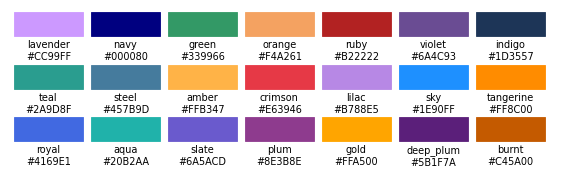

,module,role,palette names
0,paper_figures,whale_share,"(navy, green, orange, ruby)"
1,paper_figures,herding,"(teal, ruby, crimson, steel, violet)"
2,paper_figures,whale_valuation,"(steel, green, orange)"
3,paper_figures,rho_ramp,"(lavender, navy)"
4,paper_figures,herding_ramp,"(teal, amber, ruby)"
5,paper_figures,bid_ask,steel
6,paper_figures,outcome,crimson
7,paper_figures,mean_valuation,violet
8,paper_figures,volume,indigo
9,paper_figures,yes,green


In [2]:
style.apply()

# Edit the palette or the roles here (see above).


def show_palette(palette, per_row=7):
    """Swatches of every palette colour with its name and hex value."""
    rows = math.ceil(len(palette) / per_row)
    figure, ax = plt.subplots(figsize=(style.PAGE_WIDTH, 0.75 * rows))
    for index, (name, hex_value) in enumerate(palette.items()):
        row, column = divmod(index, per_row)
        ax.add_patch(plt.Rectangle((column, -row), 0.9, 0.45, color=hex_value))
        ax.text(column + 0.45, -row - 0.08, f"{name}\n{hex_value}", ha="center", va="top")
    ax.set(xlim=(-0.05, per_row), ylim=(-rows + 0.2, 0.5))
    ax.axis("off")
    plt.show()


show_palette(style.PALETTE)
pd.DataFrame(
    [("paper_figures", role, names) for role, names in pf.COLORS.items()]
    + [("stylised_mechanisms", role, names) for role, names in sm.COLORS.items()],
    columns=["module", "role", "palette names"],
)

## 3. Simulations

Each `load_*` function reads its cached runs from `sim_output/`, or reruns the simulations (and
updates the cache) when `RERUN = True` or the cache is missing. Rerunning everything takes about
25 minutes on `pf.N_WORKERS = 4` processes; the example run for Figure 1 takes a few seconds and
is never cached. Figure 1 needs no simulations beyond the Figure 2 sweep.

In [3]:
RERUN = False

# Figure 1 (stylised mechanisms) needs only the sweep, for its optional lag panel.

# Figure 2
sweep = pf.load_sweep(RERUN)                                  # B: parameter sweeps
example = pf.example_run()                                    # A, C: one market, no whale

# Figure 3
whale_shares = pf.load_whale_shares(RERUN)                    # A-C: whale capital share ρ
profit_runs, traders = pf.load_profit_experiment(RERUN)       # D: trader wealth
valuation_paths = pf.load_valuations(RERUN)                   # E: whale valuation

# Figure 4
herding = pf.load_herding(RERUN)                              # A-C: herding strength h
herding_theory = pf.load_herding(RERUN, theory=True)          # A-C under the theory's assumptions
whale_herding = pf.load_whale_herding(RERUN)                  # D-E: whale against herding (~1.5 h to rerun)

## 4. Figure 1: stylised mechanisms

How the bettor parameters shape an agent's decisions (no simulations).

- **A–B** Risk aversion: the order a bettor with valuation 0.5 submits at each limit price (A),
  and how its reservation price moves once it holds a position (B).
- **C** Stubbornness: the expected belief path toward the true outcome,
  V_t = η + (V_0 − η) s^t.
- **D** Expertise and bias: the distribution of signals a bettor receives.

Saved twice: `stylised_mechanisms_clob`, and `stylised_mechanisms_clob_lag` with the
best-matching lag for stubbornness (as in Figure 2B) after C, which moves expertise and bias to E.

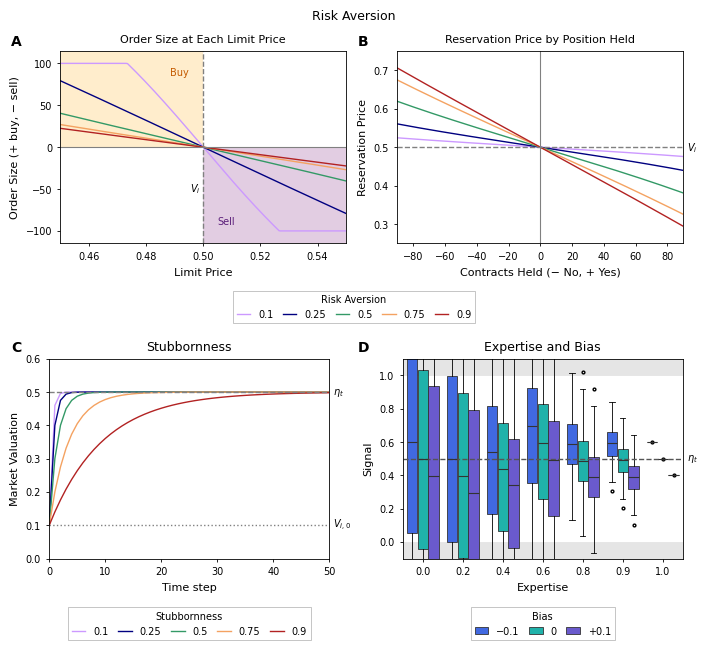

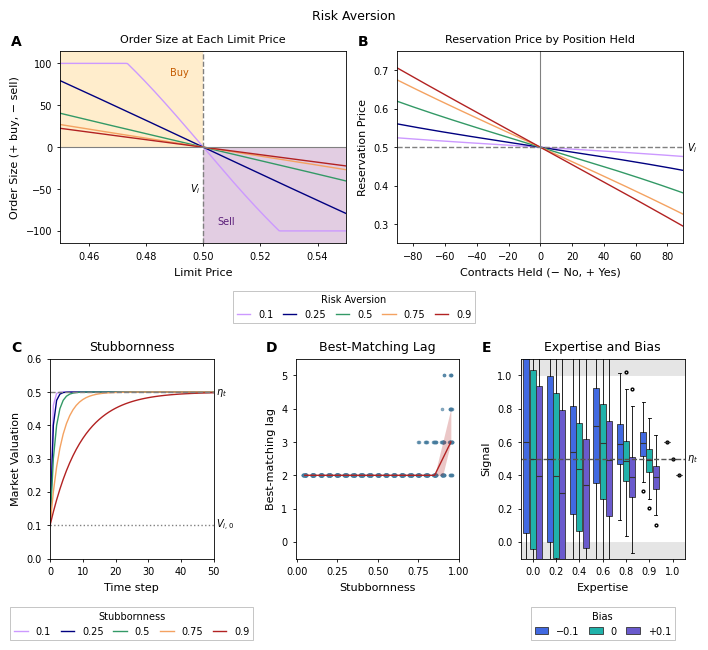

In [4]:
def figure1(with_lag=False, name="stylised_mechanisms_clob"):
    """with_lag adds the best-matching lag for stubbornness (as in Figure 2B) after panel C."""
    rng = np.random.default_rng(42)          # signals in the expertise and bias panel
    # A (risk aversion: order size | reservation price) on top, the other panels below.
    figure = plt.figure(figsize=(style.PAGE_WIDTH, 6.4), layout="constrained")
    top, bottom = figure.subfigures(2, 1, height_ratios=[1.05, 1])
    ax_a, ax_a2 = top.subplots(1, 2)
    sm.plot_order_size(ax_a)
    sm.plot_reservation(ax_a2)
    top.suptitle("Risk Aversion", fontsize=style.TITLE)
    for ax in (ax_a, ax_a2):
        ax.title.set_fontsize(style.LABEL)            # subtitles under the shared title
    top.legend(*ax_a.get_legend_handles_labels(), title="Risk Aversion",
               loc="outside lower center", ncols=len(sm.RISK_AVERSIONS))

    bottom_axes = list(bottom.subplots(1, 3 if with_lag else 2))
    ax_b, ax_c = bottom_axes[0], bottom_axes[-1]
    sm.plot_stubbornness(ax_b)
    ax_b.set_title("Stubbornness")
    ax_b.set_ylabel("Market Valuation")
    if with_lag:
        ax_lag = bottom_axes[1]
        pf.plot_lag_column(sweep, "Stubbornness", ax_lag)
        ax_lag.set_title("Best-Matching Lag")
    sm.plot_signals(ax_c, rng)
    ax_c.set_title("Expertise and Bias")
    style.label_panels(((ax_a, "A"), (ax_a2, "B"), *zip(bottom_axes, "CDE")))
    pf.save(figure, name)


figure1()
figure1(with_lag=True, name="stylised_mechanisms_clob_lag")

## 5. Figure 2: the market without a whale

- **A** One example run: the market price inside its best bid to best ask band, the election
  outcome and the mean valuation. (The budget-weighted mean valuation stays within 0.01 of the
  mean in this run, so it is not drawn.)
- **B** Parameter sweeps: mean squared error, and (right) the maximum price–fundamental
  cross-correlation over lags 0–5. Each column shares one y-axis, so the parameters compare directly.
- **C** Contracts traded per period and the capital locked in open contracts, same run.
- **D** Misclassification probability (analytic; does not depend on the market model).

`right_column` swaps B's right-hand column for `"lag"` (the lag at which the cross-correlation
is largest) or `"delay"` (the average response delay); `volume="new"` plots C as the net change in
contracts outstanding.

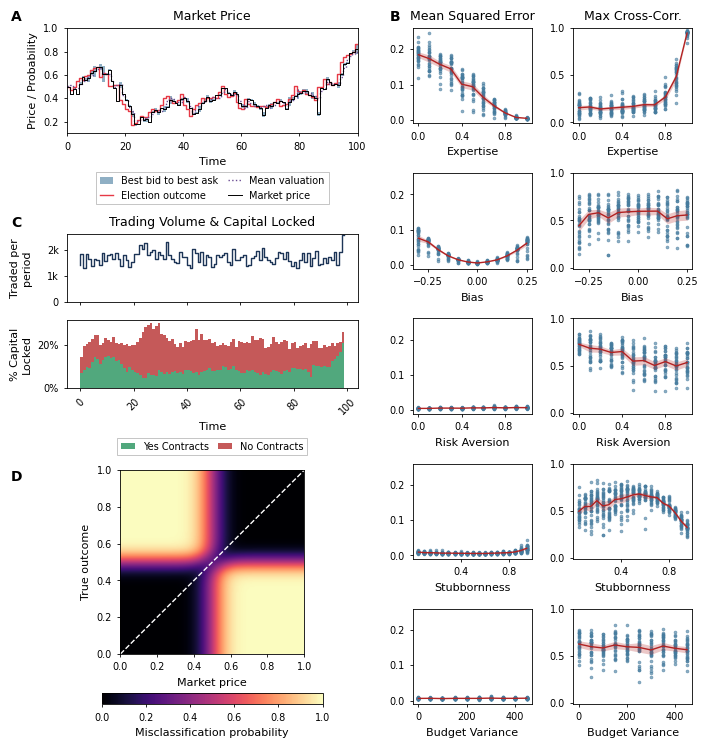

In [5]:
def figure2(right_column="cross_correlation", name="figure1_clob", volume="all"):
    # A wide left column (short panel A, C, D) and the parameter sweeps on the right.
    figure = plt.figure(figsize=(style.PAGE_WIDTH, 7.4), layout="constrained")
    left_fig, right_fig = figure.subfigures(1, 2, width_ratios=[1.15, 1], wspace=0.03)
    left = left_fig.add_gridspec(4, 1, height_ratios=[1.0, 0.65, 0.65, 1.75])
    ax_a = left_fig.add_subplot(left[0])
    ax_c = left_fig.add_subplot(left[1])
    ax_capital = left_fig.add_subplot(left[2], sharex=ax_c)
    ax_d = left_fig.add_subplot(left[3])
    pf.plot_market_price(example, ax_a)
    pf.plot_volume(example, ax_c, ax_capital, volume)
    pf.plot_misclassification(ax_d, left_fig)

    axes = right_fig.subplots(len(pf.SWEEPS), 2, sharey="col")   # one y-axis per column
    for (ax_mse, ax_right), parameter in zip(axes, pf.SWEEPS):
        pf.plot_sweep_column(sweep, parameter, "mse", "", ax_mse)
        if right_column == "lag":
            pf.plot_lag_column(sweep, parameter, ax_right)
            ax_right.set_ylabel("")
        elif right_column == "delay":
            pf.plot_sweep_column(sweep, parameter, "response_delay", "", ax_right)
            ax_right.set_ylim(bottom=-0.2)
        else:
            pf.plot_sweep_column(sweep, parameter, "peak_cross_correlation", "", ax_right)
            ax_right.set_ylim(top=1)
        for ax in (ax_mse, ax_right):
            ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    # What each column measures, once at its top, instead of a y-label on every row.
    right_titles = {"lag": "Best-Matching Lag", "delay": "Response Delay",
                    "cross_correlation": "Max Cross-Corr."}
    axes[0, 0].set_title("Mean Squared Error")
    axes[0, 1].set_title(right_titles[right_column])

    style.label_panels(((ax_a, "A"), (axes[0, 0], "B"), (ax_c, "C"), (ax_d, "D")))
    pf.save(figure, name)


figure2()

Alternative right-hand columns for panel B (supplementary):

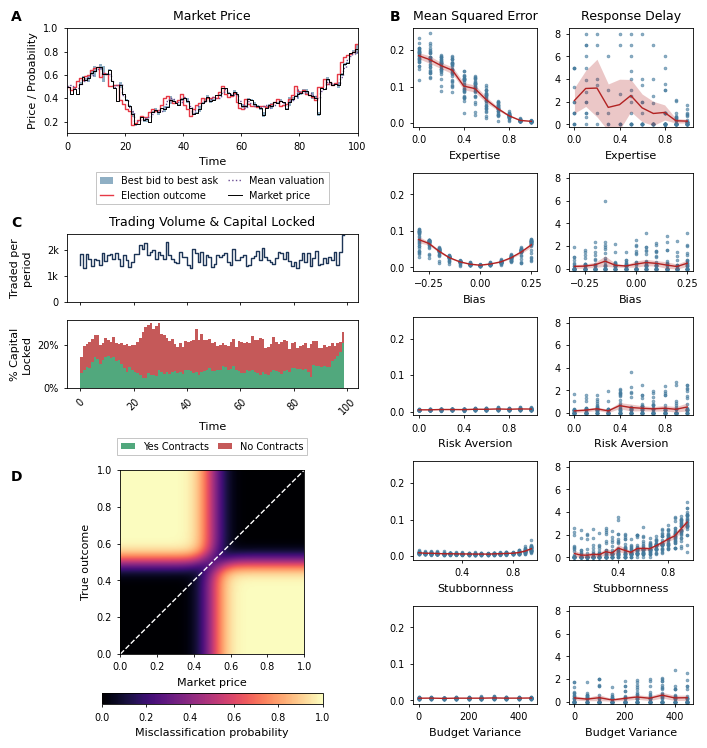

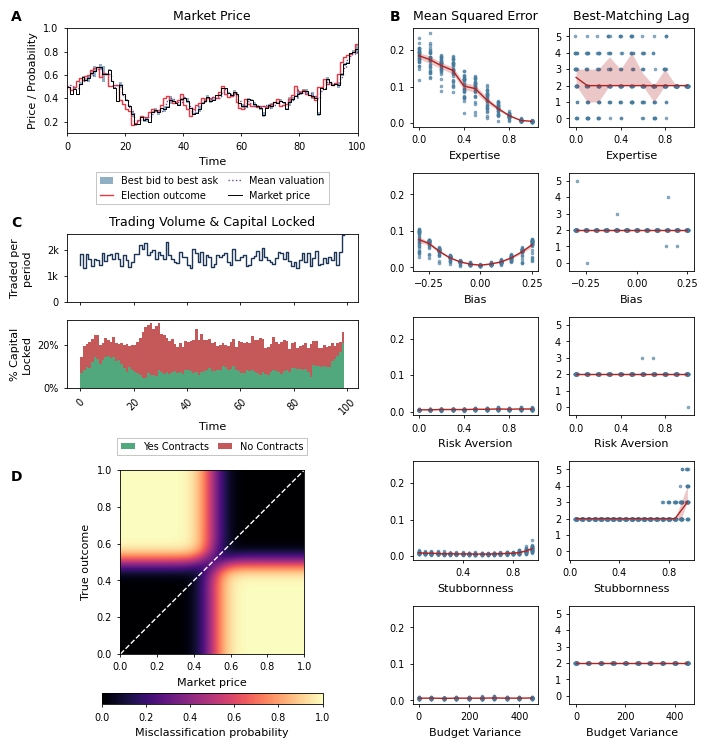

In [6]:
figure2("delay", "figure1_response_delay_clob")
figure2("lag", "figure1_best_lag_clob")

## 6. Figure 3: whale capital share

By whale capital share ρ (500 runs per ρ):

- **A** Maximum market error (P1) and **B** time with error above ordinary noise (P3):
  histograms, with each group's median as a dotted line.
- **C** Pull toward the whale's valuation (P1b; 0 = the price tracks the outcome, 1 = it sits
  at the whale's valuation): box plots.
- **D** Trader wealth by expertise and ρ.
- **E** (saved separately as `figure2e`) Mean price error after a whale shock, by whale valuation.

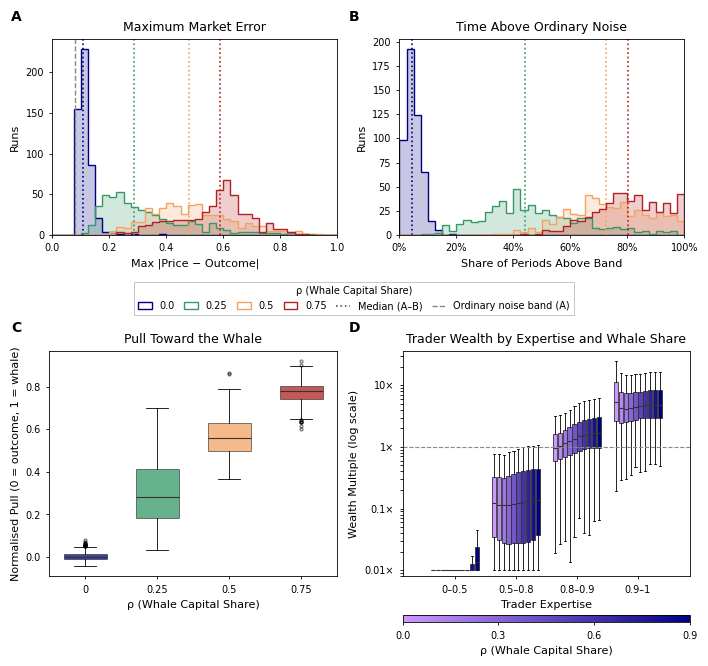

In [7]:
def figure3(name="figure2"):
    figure = plt.figure(figsize=(style.PAGE_WIDTH, 6.6), layout="constrained")
    top, bottom = figure.subfigures(2, 1, height_ratios=[1, 1.1])
    ax_a, ax_b = top.subplots(1, 2)
    ax_c, ax_d = bottom.subplots(1, 2)
    colors = pf.role_color("whale_share")
    for ax, plot in ((ax_a, plot_max_error), (ax_b, plot_time_outside_band)):
        plot(whale_shares, pf.RHO, ax, palette=colors)
        pf.style_axis(ax)
        ax.set_ylabel("Runs")
    ax_a.set(title="Maximum Market Error", xlabel="Max |Price − Outcome|")
    ax_b.set(title="Time Above Ordinary Noise", xlabel="Share of Periods Above Band")
    pf.plot_group_boxes(whale_shares, pf.RHO, "normalised_pull", ax_c, colors)
    ax_c.set(title="Pull Toward the Whale", xlabel="ρ (Whale Capital Share)",
             ylabel="Normalised Pull (0 = outcome, 1 = whale)")
    pf.style_axis(ax_c)

    # One legend under A-B: the ρ colours, the medians and the ordinary band.
    entries = pf.group_legend_entries((ax_a, ax_b))
    band = entries.pop("Ordinary noise band (A)")
    entries["Median (A–B)"] = Line2D([], [], color="#555555", linestyle=":", linewidth=1.2)
    entries["Ordinary noise band (A)"] = band
    top.legend(list(entries.values()), list(entries), title="ρ (Whale Capital Share)",
               loc="outside lower center", ncols=len(entries))

    pf.plot_trader_returns(traders, ax_d, title="Trader Wealth by Expertise and Whale Share")
    ax_d.set_ylabel("Wealth Multiple (log scale)")
    pf.rho_colorbar(bottom, ax_d, list(pf.PROFIT_SHOWN_SHARES))
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.98))    # headroom for the raised letters
    style.label_panels(((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")), lift=8)
    pf.save(figure, name)


figure3()

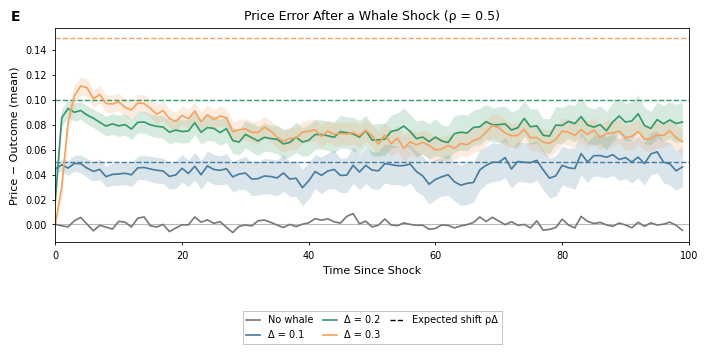

In [8]:
figure, ax_e = plt.subplots(figsize=(style.PAGE_WIDTH, 3.4), layout="constrained")
pf.plot_valuation_paths(valuation_paths, ax_e)
style.label_panels(((ax_e, "E"),))
pf.save(figure, "figure2e")

Supplementary: panel D's layout with trader risk aversion on the x-axis.

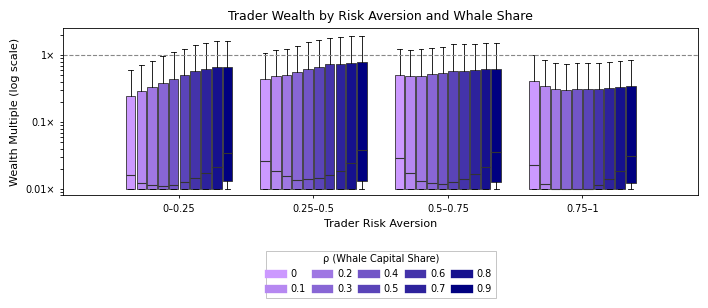

In [9]:
figure, ax = plt.subplots(figsize=(style.PAGE_WIDTH, 3.0), constrained_layout=True)
pf.plot_trader_returns(traders, ax, column="risk_aversion", groups=pf.RISK_AVERSION_GROUPS,
                       xlabel="Trader Risk Aversion",
                       title="Trader Wealth by Risk Aversion and Whale Share")
pf.save(figure, "trader_wealth_by_risk_aversion")

## 7. Figure 4: herding

- **A** Maximum error, **B** time above noise and **C** steady-state error (mean |price − outcome|
  over the last 50 periods), one row per herding strength h: a whale with ρ = 0.3
  trades from period 0 against 100 bettors with herding h (500 runs per h, each h judged against
  the band of its own no-whale runs).
- **D** Steady-state price error against the whale's initial capital share, by herding strength:
  theory (lines) and simulation (points, 95% intervals), stubbornness 0.1.
- **E** Mean maximum price error by herding strength and stubbornness, whale share 0.3.

D–E have everyone at log utility, the true outcome fixed at 0.5, exact signals and the whale
(valuation 0.7) trading from period 0; 200 runs per condition.

A–C are drawn twice: the original design (whale valuation 1, mixed risk aversion; `figure3b`)
and the theory's assumptions (whale valuation 0.7, log utility for everyone; `figure3b_theory`).

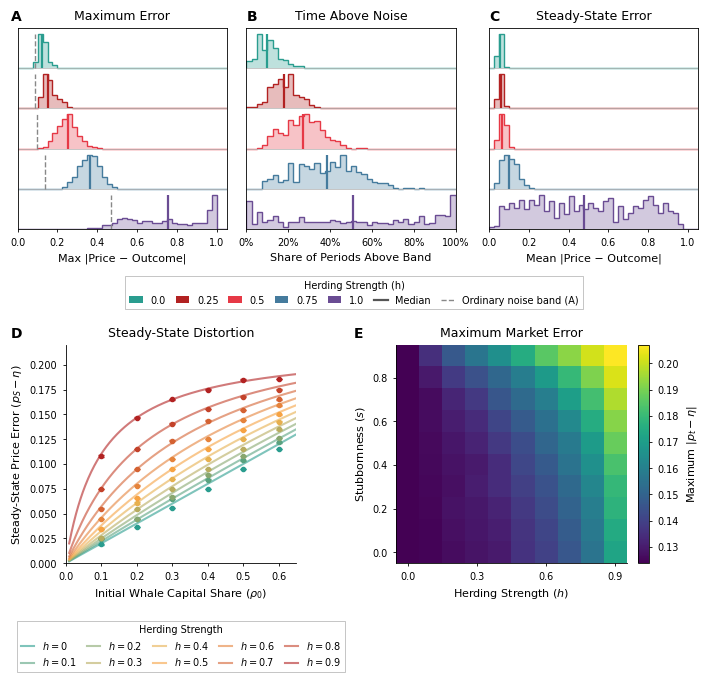

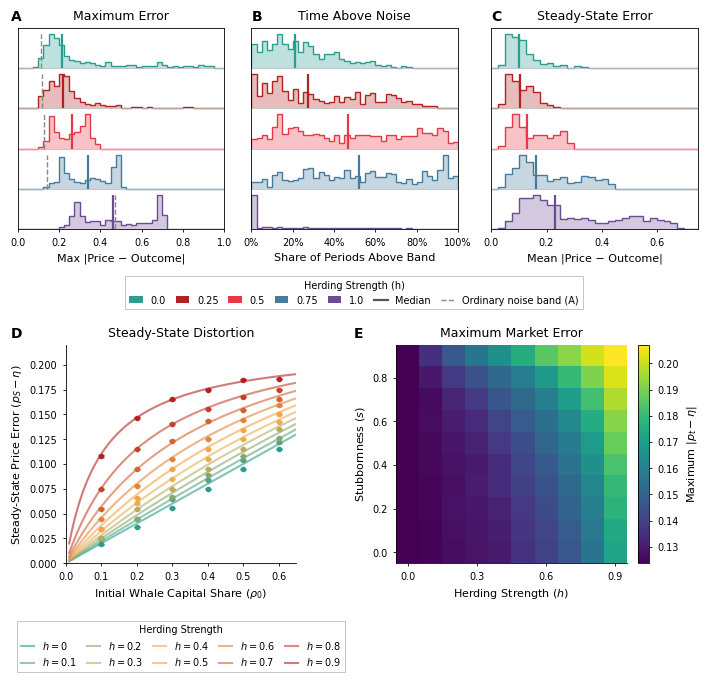

In [10]:
def figure4(metrics, name):
    heights = [2.9, 3.3]
    figure = plt.figure(figsize=(style.PAGE_WIDTH, sum(heights) + 0.5), layout="constrained")
    # Rows as separate subfigures, so each row is laid out on its own.
    top, bottom = figure.subfigures(2, 1, height_ratios=heights)
    axes = list(top.subplots(1, 3))
    panels = (
        (plot_max_error, "Maximum Error", "Max |Price − Outcome|"),
        (plot_time_outside_band, "Time Above Noise", "Share of Periods Above Band"),
        (plot_steady_state_error, "Steady-State Error", "Mean |Price − Outcome|"),
    )
    for ax, (plot, title, xlabel) in zip(axes, panels):
        plot(metrics, pf.HERDING, ax, palette=pf.role_color("herding"), layout="ridge",
             row_labels=False)
        ax.set(title=title, xlabel=xlabel, ylabel="")
        pf.style_axis(ax)

    # One legend under the row: group colours as filled boxes, the medians, the ordinary band.
    entries = pf.group_legend_entries(axes)
    band = entries.pop("Ordinary noise band (A)")
    entries = {name: Patch(facecolor=handle.get_edgecolor(), edgecolor="none")
               for name, handle in entries.items()}
    entries["Median"] = Line2D([], [], color="#555555", linewidth=1.6)
    entries["Ordinary noise band (A)"] = band
    top.legend(list(entries.values()), list(entries), title="Herding Strength (h)",
               loc="outside lower center", ncols=len(entries))

    # D-E: the whale against herding bettors, with the theory.
    ax_d, ax_e = bottom.subplots(1, 2)
    pf.plot_steady_state_distortion(whale_herding, ax_d)
    ax_d.legend(title="Herding Strength", loc="upper center", bbox_to_anchor=(0.5, -0.24),
                ncols=5)
    pf.plot_max_error_map(whale_herding, ax_e, bottom)
    for ax in (ax_d, ax_e):
        ax.spines[["top", "right"]].set_visible(False)
    style.label_panels([*zip(axes, "ABC"), (ax_d, "D"), (ax_e, "E")])
    pf.save(figure, name)


figure4(herding, "figure3b")
figure4(herding_theory, "figure3b_theory")